# Praktikum 5 — Benchmark Annoy vs FAISS IVF vs HNSW

## Tujuan
Membandingkan trade-off **Recall@10** dan **waktu query** pada tiga pendekatan pencarian approximate nearest neighbors:
- **Annoy**
- **FAISS IVF-Flat**
- **HNSW (hnswlib)**

Notebook ini mengikuti skenario praktikum: dataset vektor acak, ground truth dari FAISS brute force (`IndexFlatL2`), variasi parameter pencarian, dan grafik recall versus waktu query.

**Catatan interpretasi:** grafik di notebook menggunakan sumbu X = Recall@10 dan sumbu Y = waktu query dalam ms/query pada skala logaritmik. Waktu lebih kecil berarti lebih cepat, sehingga titik yang lebih baik cenderung berada di kanan-bawah. Kode sumber praktikum membalik sumbu Y agar visualisasi trade-off mudah dibaca. Karena ini bukan pengukuran dari Docker/ANN-Benchmarks resmi, hasilnya adalah benchmark sederhana pada runtime tempat notebook dijalankan.


In [17]:
# Instalasi dependensi di Google Colab
!pip -q install annoy faiss-cpu hnswlib pandas


In [18]:
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import faiss
from annoy import AnnoyIndex
import hnswlib

# -------------------------------
# Konfigurasi eksperimen
# -------------------------------
SEED = 42
D = 128
NB = 100_000      # jumlah database vector; sesuai contoh praktikum
NQ = 1_000        # jumlah query
K = 10

# Jika runtime Colab memiliki RAM terbatas, turunkan NB ke 20_000 atau 50_000.
ANNOY_TREES = 10
ANNOY_SEARCH_K_VALUES = [200, 500, 1000, 2000]
FAISS_NLIST = 100
FAISS_NPROBE_VALUES = [1, 5, 10, 20]
HNSW_EF_VALUES = [50, 100, 200, 400]
HNSW_M = 16
HNSW_EF_CONSTRUCTION = 200

rng = np.random.default_rng(SEED)
xb = rng.random((NB, D), dtype=np.float32)
xq = rng.random((NQ, D), dtype=np.float32)

print(f"Dataset: {NB:,} database vector × {D} dimensi")
print(f"Query: {NQ:,} × {D} dimensi; k={K}")


Dataset: 100,000 database vector × 128 dimensi
Query: 1,000 × 128 dimensi; k=10


## 1. Ground truth dengan exact nearest neighbors

`IndexFlatL2` menghitung jarak L2 ke seluruh database. Indeks tetangga terdekatnya digunakan sebagai ground truth untuk menghitung Recall@10 pada metode approximate.

In [19]:
flat = faiss.IndexFlatL2(D)
flat.add(xb)

t0 = time.perf_counter()
_, gt_idx = flat.search(xq, K)
ground_truth_seconds = time.perf_counter() - t0

print(f"Waktu membuat exact index dan memasukkan data: selesai")
print(f"Waktu pencarian ground truth untuk {NQ:,} query: {ground_truth_seconds:.3f} detik")


Waktu membuat exact index dan memasukkan data: selesai
Waktu pencarian ground truth untuk 1,000 query: 1.468 detik


In [20]:
def recall_at_k(I_pred, I_gt, k=K):
    """Recall agregat: jumlah tetangga ground truth yang ditemukan / total target."""
    correct = 0
    for pred, truth in zip(I_pred, I_gt):
        correct += len(set(np.asarray(pred[:k]).tolist()) & set(np.asarray(truth[:k]).tolist()))
    return correct / (len(I_pred) * k)


def benchmark_annoy(xb, xq, search_k, gt_idx, k=K):
    d = xb.shape[1]
    index = AnnoyIndex(d, "euclidean")

    t0 = time.perf_counter()
    for i, v in enumerate(xb):
        index.add_item(i, v.tolist())
    index.build(ANNOY_TREES)
    build_seconds = time.perf_counter() - t0

    query_ids = []
    t0 = time.perf_counter()
    for v in xq:
        ids = index.get_nns_by_vector(v.tolist(), k, search_k=search_k)
        # Annoy seharusnya mengembalikan k hasil, tetapi pad jika hasil tidak lengkap.
        query_ids.append(ids[:k])
    query_seconds = time.perf_counter() - t0

    recall = recall_at_k(query_ids, gt_idx, k)
    avg_ms = query_seconds * 1000 / len(xq)
    return {
        "Metode": "Annoy",
        "Parameter": f"search_k={search_k}, trees={ANNOY_TREES}",
        "Parameter utama": search_k,
        "Recall@10": recall,
        "Query time (ms/query)": avg_ms,
        "QPS": len(xq) / query_seconds if query_seconds > 0 else np.inf,
        "Build time (s)": build_seconds
    }


def benchmark_faiss_ivf(xb, xq, nprobe, gt_idx, k=K):
    d = xb.shape[1]
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, FAISS_NLIST, faiss.METRIC_L2)

    t0 = time.perf_counter()
    index.train(xb)
    index.add(xb)
    build_seconds = time.perf_counter() - t0

    index.nprobe = nprobe
    t0 = time.perf_counter()
    _, I = index.search(xq, k)
    query_seconds = time.perf_counter() - t0

    recall = recall_at_k(I, gt_idx, k)
    avg_ms = query_seconds * 1000 / len(xq)
    return {
        "Metode": "FAISS IVF-Flat",
        "Parameter": f"nprobe={nprobe}, nlist={FAISS_NLIST}",
        "Parameter utama": nprobe,
        "Recall@10": recall,
        "Query time (ms/query)": avg_ms,
        "QPS": len(xq) / query_seconds if query_seconds > 0 else np.inf,
        "Build time (s)": build_seconds
    }


def benchmark_hnsw(xb, xq, ef, gt_idx, k=K):
    d = xb.shape[1]
    index = hnswlib.Index(space="l2", dim=d)

    t0 = time.perf_counter()
    index.init_index(
        max_elements=xb.shape[0],
        ef_construction=HNSW_EF_CONSTRUCTION,
        M=HNSW_M,
        random_seed=SEED
    )
    index.add_items(xb, np.arange(xb.shape[0]))
    build_seconds = time.perf_counter() - t0

    index.set_ef(max(ef, k))
    t0 = time.perf_counter()
    I, _ = index.knn_query(xq, k=k)
    query_seconds = time.perf_counter() - t0

    recall = recall_at_k(I, gt_idx, k)
    avg_ms = query_seconds * 1000 / len(xq)
    return {
        "Metode": "HNSW",
        "Parameter": f"ef={ef}, M={HNSW_M}",
        "Parameter utama": ef,
        "Recall@10": recall,
        "Query time (ms/query)": avg_ms,
        "QPS": len(xq) / query_seconds if query_seconds > 0 else np.inf,
        "Build time (s)": build_seconds
    }


## 2. Jalankan benchmark dengan variasi parameter

Setiap titik pada grafik merepresentasikan satu konfigurasi. Build time diukur dan dilaporkan, tetapi tidak dimasukkan ke waktu query karena yang dibandingkan pada grafik adalah performa pencarian setelah indeks siap.

In [13]:
results = []

for search_k in ANNOY_SEARCH_K_VALUES:
    print(f"Annoy: search_k={search_k}")
    results.append(benchmark_annoy(xb, xq, search_k, gt_idx))

for nprobe in FAISS_NPROBE_VALUES:
    print(f"FAISS IVF-Flat: nprobe={nprobe}")
    results.append(benchmark_faiss_ivf(xb, xq, nprobe, gt_idx))

for ef in HNSW_EF_VALUES:
    print(f"HNSW: ef={ef}")
    results.append(benchmark_hnsw(xb, xq, ef, gt_idx))

results_df = pd.DataFrame(results)
display(results_df[[
    "Metode", "Parameter", "Recall@10",
    "Query time (ms/query)", "QPS", "Build time (s)"
]])


HNSW: ef=400


,Metode,Parameter,Recall@10,Query time (ms/query),QPS,Build time (s)
0,Annoy,"search_k=200, trees=10",0.0234,0.122621,8155.194061,2.507489
1,Annoy,"search_k=500, trees=10",0.0452,0.240420,4159.394485,5.169768
2,Annoy,"search_k=1000, trees=10",0.0772,0.468796,2133.125805,3.644028
3,Annoy,"search_k=2000, trees=10",0.1258,0.397410,2516.291516,1.505793
4,FAISS IVF-Flat,"nprobe=1, nlist=100",0.0544,0.053630,18646.315531,0.303168
5,FAISS IVF-Flat,"nprobe=5, nlist=100",0.1952,0.195860,5105.691386,0.322160
6,FAISS IVF-Flat,"nprobe=10, nlist=100",0.3178,0.405548,2465.801138,0.307747
7,FAISS IVF-Flat,"nprobe=20, nlist=100",0.5031,1.188015,841.740348,0.310729
8,HNSW,"ef=50, M=16",0.3022,0.167449,5971.954174,76.852449
9,HNSW,"ef=100, M=16",0.4398,0.555223,1801.077227,74.056500


Annoy: search_k=200
Annoy: search_k=500
Annoy: search_k=1000
Annoy: search_k=2000


## 3. Grafik Recall vs Query Time

Sumbu Y menggunakan skala logaritmik. Sumbu dibalik agar waktu query yang lebih rendah tampil di bagian bawah, sehingga titik di kanan-bawah mengindikasikan kombinasi recall tinggi dan waktu query rendah.

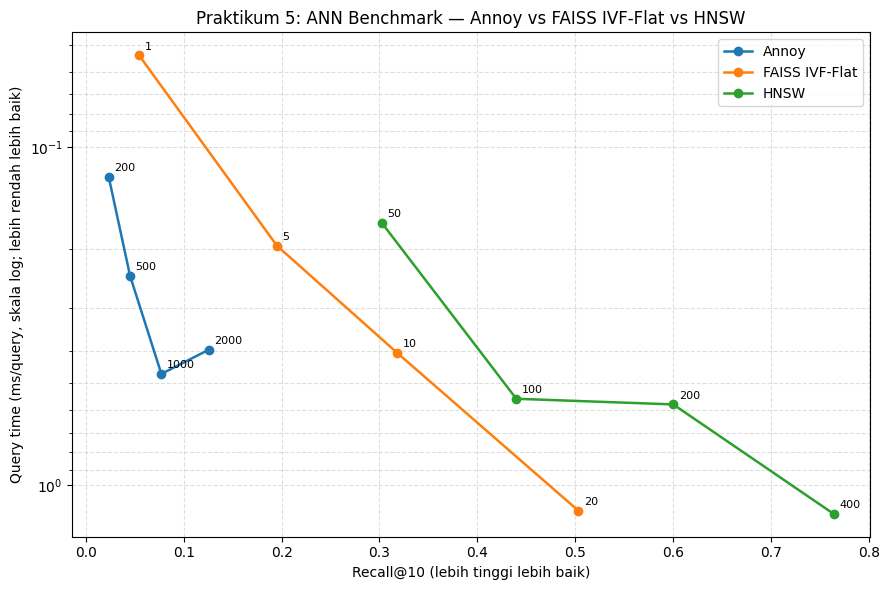

In [14]:
plt.figure(figsize=(9, 6))

for method in results_df["Metode"].unique():
    subset = results_df[results_df["Metode"] == method].sort_values("Recall@10")
    plt.plot(
        subset["Recall@10"],
        subset["Query time (ms/query)"],
        marker="o",
        linewidth=1.8,
        label=method
    )
    for _, row in subset.iterrows():
        plt.annotate(
            str(row["Parameter utama"]),
            (row["Recall@10"], row["Query time (ms/query)"]),
            textcoords="offset points",
            xytext=(4, 4),
            fontsize=8
        )

plt.xlabel("Recall@10 (lebih tinggi lebih baik)")
plt.ylabel("Query time (ms/query, skala log; lebih rendah lebih baik)")
plt.yscale("log")
plt.gca().invert_yaxis()
plt.title("Praktikum 5: ANN Benchmark — Annoy vs FAISS IVF-Flat vs HNSW")
plt.grid(True, which="both", linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()


## 4. Grafik Recall vs QPS (opsional)

QPS (*queries per second*) adalah kebalikan dari waktu rata-rata per query secara agregat. Grafik ini menggunakan sumbu Y QPS; nilai lebih tinggi berarti lebih cepat.

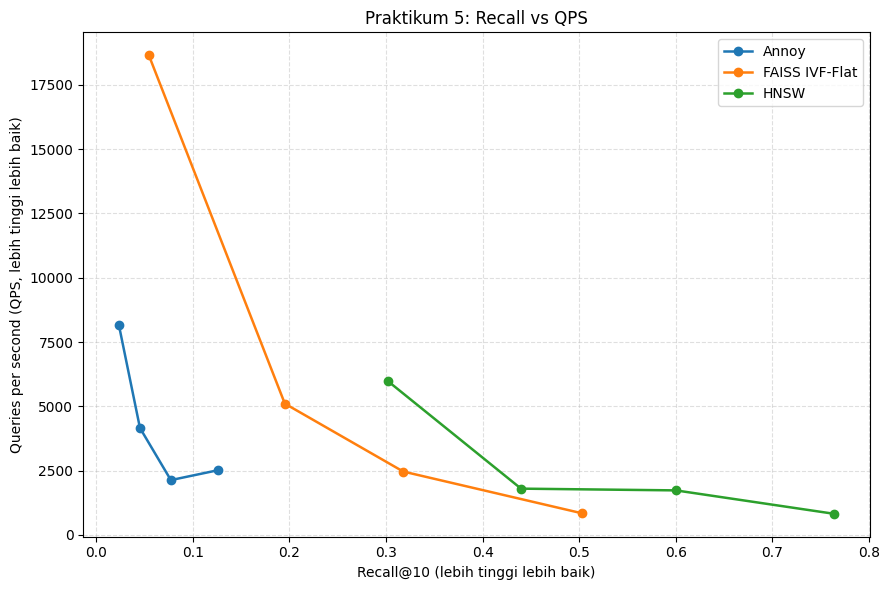

In [15]:
plt.figure(figsize=(9, 6))

for method in results_df["Metode"].unique():
    subset = results_df[results_df["Metode"] == method].sort_values("Recall@10")
    plt.plot(
        subset["Recall@10"],
        subset["QPS"],
        marker="o",
        linewidth=1.8,
        label=method
    )

plt.xlabel("Recall@10 (lebih tinggi lebih baik)")
plt.ylabel("Queries per second (QPS, lebih tinggi lebih baik)")
plt.title("Praktikum 5: Recall vs QPS")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()


## 5. Ekspor tabel hasil

Tabel hasil dapat diunduh sebagai CSV untuk dimasukkan ke laporan. Angka harus berasal dari runtime yang benar-benar dijalankan.

In [16]:
csv_path = "hasil_praktikum_5_ann_benchmark.csv"
results_df.to_csv(csv_path, index=False)
print("Hasil tersimpan ke:", csv_path)
display(results_df)


Hasil tersimpan ke: hasil_praktikum_5_ann_benchmark.csv


,Metode,Parameter,Parameter utama,Recall@10,Query time (ms/query),QPS,Build time (s)
0,Annoy,"search_k=200, trees=10",200,0.0234,0.122621,8155.194061,2.507489
1,Annoy,"search_k=500, trees=10",500,0.0452,0.240420,4159.394485,5.169768
2,Annoy,"search_k=1000, trees=10",1000,0.0772,0.468796,2133.125805,3.644028
3,Annoy,"search_k=2000, trees=10",2000,0.1258,0.397410,2516.291516,1.505793
4,FAISS IVF-Flat,"nprobe=1, nlist=100",1,0.0544,0.053630,18646.315531,0.303168
5,FAISS IVF-Flat,"nprobe=5, nlist=100",5,0.1952,0.195860,5105.691386,0.322160
6,FAISS IVF-Flat,"nprobe=10, nlist=100",10,0.3178,0.405548,2465.801138,0.307747
7,FAISS IVF-Flat,"nprobe=20, nlist=100",20,0.5031,1.188015,841.740348,0.310729
8,HNSW,"ef=50, M=16",50,0.3022,0.167449,5971.954174,76.852449
9,HNSW,"ef=100, M=16",100,0.4398,0.555223,1801.077227,74.056500


## Panduan analisis

1. **Recall@10** mengukur proporsi tetangga exact yang ditemukan kembali oleh algoritma approximate.
2. **Query time** adalah waktu rata-rata per query; lebih rendah berarti lebih cepat.
3. **QPS** adalah jumlah query yang dapat dilayani per detik; lebih tinggi berarti lebih cepat.
4. Pada Annoy, `search_k` mengatur jumlah node yang diperiksa saat pencarian. Nilai lebih tinggi biasanya meningkatkan recall dengan biaya query lebih lama.
5. Pada FAISS IVF-Flat, `nprobe` menentukan banyaknya cluster yang diperiksa. Nilai lebih tinggi biasanya meningkatkan recall, tetapi menambah waktu pencarian.
6. Pada HNSW, `ef` mengendalikan ukuran kandidat yang dipertimbangkan. Nilai lebih tinggi biasanya meningkatkan recall dan menambah biaya query.
7. **Build time** adalah biaya awal membangun indeks. Pada kode ini FAISS IVF mencakup training dan penambahan data; Annoy mencakup penambahan item dan build; HNSW mencakup inisialisasi dan penambahan data.
8. Hasil dapat berbeda karena CPU, RAM, jumlah thread, dan kondisi runtime. Untuk laporan yang lebih stabil, jalankan ulang eksperimen atau gunakan median dari beberapa pengulangan.
9. Benchmark ini adalah simulasi sederhana di Colab, bukan hasil resmi repository `ann-benchmarks`.
